# 2D Burgers equation: data generation

The benchmark of Gkimisis, Pontes Duff, Goyal and Benner (2026), their equation (22).
Only what differs from problems 1 and 2 is explained; the observation protocol and the
compression are identical.


In [1]:
import numpy as np
import scipy.sparse as sparse
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
import time

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# --------------------- Experiment configuration  -------------------
P = 1.0                    # side of the square domain, as in the reference
KAPPA = 0.2                # coefficient of w (w_x + w_y), the reference's c
NU = 2e-3                  # viscosity
NX = 50                    # grid points per direction: dx = 0.02, as in the reference

# Parameters (a, b) = (amplitude, weight of the second harmonic) of the initial field:
# the four corners and the centre of [0.4, 0.6] x [0, 0.4].  The amplitude sets how
# convective the problem is; see section 5.1 for why it is kept below the reference's
# own value of 1.
TRAIN_PARAMS = [(0.4, 0.0), (0.6, 0.0), (0.4, 0.4), (0.6, 0.4), (0.5, 0.2)]
TEST_PARAMS = (0.55, 0.1)  # new parameters, used only for testing

T_TRAIN = (0.0, 2.0)       # time window in which data are observed
T_FINAL = 4.0              # end of the prediction window, as in the reference
NUM_TRUTH_TIMES = 201      # output times on [0, T_FINAL] for the reference solution

M = 30                     # number of noisy snapshots per trajectory (section 4.1)
XI = 0.03                  # relative noise level (3 %)
R = 6                      # number of POD modes
M_PRIME = 2 * M            # number of times at which the GP derivatives will be evaluated

DT = 0.01                  # step of the implicit midpoint rule (section 3)
NEWTON_TOL = 1e-13         # relative residual at which the Newton iteration stops
SEED = 20261022            # random seed

dx = P / NX                # = dy; the grid is uniform and isotropic
n = NX * NX                # full-order state dimension

print(f"kappa = {KAPPA:g},  nu = {NU:g}")
print(f"domain [0, {P:g})^2,  {NX} x {NX} grid,  dx = dy = {dx:g},  n = {n}")
print(f"m = {M},  xi = {XI:.0%},  train on [0, {T_TRAIN[1]:g}], predict to {T_FINAL:g}")

kappa = 0.2,  nu = 0.002
domain [0, 1)^2,  50 x 50 grid,  dx = dy = 0.02,  n = 2500
m = 30,  xi = 3%,  train on [0, 2], predict to 4


## 1. The PDE

$$
\frac{\partial w}{\partial t}
 = \kappa\,w\Big(\frac{\partial w}{\partial x}+\frac{\partial w}{\partial y}\Big)
 + \nu\Big(\frac{\partial^2 w}{\partial x^2}+\frac{\partial^2 w}{\partial y^2}\Big),
\qquad (x,y)\in[0,1)^2,
$$

periodic in both directions. The state is a scalar field, as in problems 1 and 2; what is new is
that it is transported in two directions at once.

### 1.1 Energy

With $E=\tfrac12\iint w^2$,

$$
\frac{\mathrm dE}{\mathrm dt}
 = \kappa\iint w^2\Big(\frac{\partial w}{\partial x}+\frac{\partial w}{\partial y}\Big)\,\mathrm dx\,\mathrm dy
 + \nu\iint w\,\Delta w\,\mathrm dx\,\mathrm dy
 = -\nu\iint\|\nabla w\|^2\,\mathrm dx\,\mathrm dy ,
$$

the convective part vanishing one direction at a time:
$\int_0^1 w^2w_x\,\mathrm dx=[w^3/3]_0^1=0$ by periodicity, and the same in $y$. Convection
preserves the energy and viscosity dissipates it, so $E$ decreases monotonically. This is the
difference from problem 2.

### 1.2 Grid and state vector

Nodes $x_i=i\,\Delta x$, $y_j=j\,\Delta x$ for $i,j=0,\dots,N-1$, all indices read modulo $N$ so
that the square is a torus. The $w_{ij}(t)$ are flattened in C order, $k=iN+j$, giving
$\mathbf q\in\mathbb R^{N^2}$.

### 1.3 Initial condition

$$
w(x,y,0;a,b) = a\big(\cos 2\pi x\,\cos 2\pi y + b\,\cos 4\pi x\,\cos 4\pi y\big),
$$

periodic in both directions and of zero mean. The amplitude $a$ ranges over
$[0.4,0.6]$ and the second-harmonic weight $b$ over $[0,0.4]$.


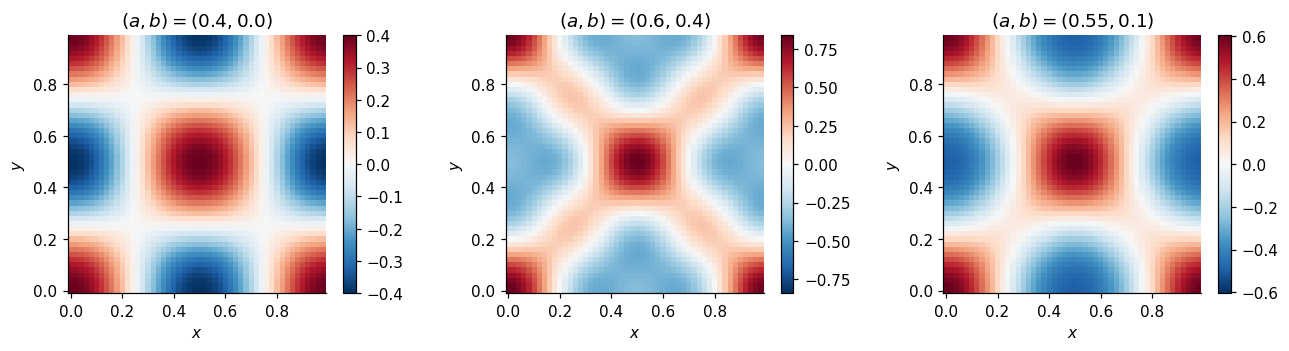

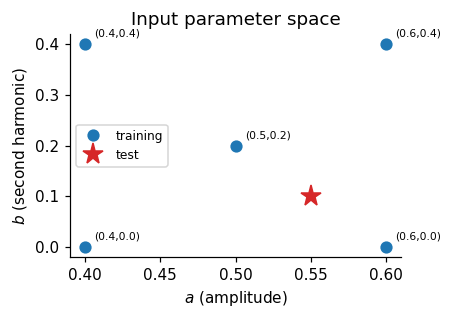

In [2]:
x = np.linspace(0.0, P, NX, endpoint=False)   # x = P is NOT a node (it is x_0)
y = x.copy()
X, Y = np.meshgrid(x, y, indexing="ij")       # X[i, j] = x_i, Y[i, j] = y_j

def initial_condition(a, b):
    """The initial field as a flat vector of length n."""
    w = a * (np.cos(2*np.pi*X) * np.cos(2*np.pi*Y)
             + b * np.cos(4*np.pi*X) * np.cos(4*np.pi*Y))
    return w.ravel()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.1))
for ax, params in zip(axes, [TRAIN_PARAMS[0], TRAIN_PARAMS[3], TEST_PARAMS]):
    w0 = initial_condition(*params).reshape(NX, NX)
    im = ax.pcolormesh(X, Y, w0, shading="auto", cmap="RdBu_r",
                       vmin=-np.abs(w0).max(), vmax=np.abs(w0).max())
    ax.set(xlabel="$x$", ylabel="$y$", title=f"$(a,b)={params}$", aspect="equal")
    fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

Pm_box = np.array(TRAIN_PARAMS)
fig, ax = plt.subplots(figsize=(4.2, 3))
ax.plot(Pm_box[:, 0], Pm_box[:, 1], "o", ms=7, label="training")
ax.plot(*TEST_PARAMS, "*", ms=14, color="C3", label="test")
for a, b in TRAIN_PARAMS:
    ax.annotate(f"({a},{b})", (a, b), textcoords="offset points", xytext=(6, 5), fontsize=7)
ax.set(xlabel=r"$a$ (amplitude)", ylabel=r"$b$ (second harmonic)",
       title="Input parameter space")
ax.legend(fontsize=8, loc="center left")
plt.tight_layout(); plt.show()

## 2. From the PDE to a system of ODEs

Discretizing in space only, the PDE becomes

$$
\boxed{\ \frac{\mathrm d\mathbf q}{\mathrm dt}=\mathbf A_F\mathbf q+\mathbf H_F(\mathbf q\otimes\mathbf q)\ }
$$

with no input, as in problem 2. Both stencils use only the four axis neighbours of a node.

### 2.1 The equation at one node

The unknowns are the nodal values $w_{ij}(t)\approx w(x_i,y_j,t)$, $N^2$ of them, defined by the
ODEs written here rather than sampled from a known solution. Each derivative becomes its
difference formula at the node, indices read modulo $N$, which is how periodicity enters: the
five-point Laplacian for the viscous term, the $\lambda=\tfrac23$ split of problem 1 for the
convective one, applied once per direction.

$$
\begin{aligned}
\frac{\mathrm dw_{ij}}{\mathrm dt}=\;
&\frac{\kappa}{6\Delta x}\Big[\big(w_{i+1,j}^{2}-w_{i-1,j}^{2}\big)+\big(w_{i,j+1}^{2}-w_{i,j-1}^{2}\big)\Big]\\[2pt]
+\;&\frac{\kappa}{6\Delta x}\,w_{ij}\Big[\big(w_{i+1,j}-w_{i-1,j}\big)+\big(w_{i,j+1}-w_{i,j-1}\big)\Big]\\[2pt]
+\;&\frac{\nu}{\Delta x^{2}}\Big[w_{i+1,j}+w_{i-1,j}+w_{i,j+1}+w_{i,j-1}-4w_{ij}\Big].
\end{aligned}
$$

The coefficient is $\tfrac{\kappa}{6\Delta x}=\kappa\cdot\tfrac13\cdot\tfrac1{2\Delta x}$: the
$\tfrac13$ from $\lambda=\tfrac23$, the $\tfrac1{2\Delta x}$ from the centred difference.

### 2.2 The state vector, and the neighbours as index offsets

The $w_{ij}$ form a square array; a solver wants a vector. With the C-order flattening of
section 1.2,

$$
q_k:=w_{ij},\qquad k=iN+j,\qquad i=\lfloor k/N\rfloor,\qquad j=k\bmod N,
$$

the neighbours become index offsets that wrap differently in the two directions. The
$x$-neighbours $(i\pm1,j)$ are $k\pm N$, one full row away in the vector, wrapped modulo
$n=N^2$; the $y$-neighbours $(i,j\pm1)$ are the adjacent entries $k\pm1$, wrapped modulo $N$
*within the row*: $k+1\to k+1-N$ when $j=N-1$, and $k-1\to k-1+N$ when $j=0$. With those
conventions the node equation is the $k$-th component of the system:

$$
\begin{aligned}
\frac{\mathrm dq_k}{\mathrm dt}=\;
&\frac{\kappa}{6\Delta x}\Big[q_{k+N}^{2}-q_{k-N}^{2}+q_{k+1}^{2}-q_{k-1}^{2}\Big]\\[2pt]
+\;&\frac{\kappa}{6\Delta x}\,q_k\Big[q_{k+N}-q_{k-N}+q_{k+1}-q_{k-1}\Big]\\[2pt]
+\;&\frac{\nu}{\Delta x^{2}}\Big[q_{k+N}+q_{k-N}+q_{k+1}+q_{k-1}-4q_k\Big],
\qquad k=0,\dots,N^2-1 .
\end{aligned}
$$

With $N=3$, so $n=9$ and three entries per row, both wraps fire at $k=2$, that is $(i,j)=(0,2)$:
$k+N=5$, $k-N=-1\to8$, $k+1=3\to0$, $k-1=1$, and

$$\frac{\mathrm dq_2}{\mathrm dt}=\frac{\kappa}{6\Delta x}\Big[q_5^2-q_8^2+q_0^2-q_1^2
  +q_2\big(q_5-q_8+q_0-q_1\big)\Big]
  +\frac{\nu}{\Delta x^2}\Big[q_5+q_8+q_0+q_1-4q_2\Big].$$

Taking $k+1=3$ would have picked the first entry of the *next* row, the wrong node: that is why
the $y$-wrap is modulo $N$ and not modulo $n$.

### 2.3 Reading off the two operators

The last bracket above is linear in $\mathbf q$ and the first two quadratic, so both operators
can be read off directly.

**The linear part** is $\mathbf A_F=\nu\mathbf L$ with five nonzeros per row,

$$
L_{k,k}=-\frac{4}{\Delta x^2},\qquad
L_{k,\,k\pm N}=L_{k,\,k\pm 1}=\frac{1}{\Delta x^2},
$$

which is easier to assemble from the four shift matrices, the permutations with
$(\mathbf S^\pm_x\mathbf q)_k=q_{k\pm N}$ and $(\mathbf S^\pm_y\mathbf q)_k=q_{k\pm1}$, built as
Kronecker products of the $N\times N$ cyclic shifts $\mathbf P^\pm$:

$$
\mathbf S^\pm_x=\mathbf P^\pm\otimes\mathbf I,\qquad
\mathbf S^\pm_y=\mathbf I\otimes\mathbf P^\pm ,\qquad
\mathbf L=\frac{\mathbf S^+_x+\mathbf S^-_x+\mathbf S^+_y+\mathbf S^-_y-4\,\mathbf I}{\Delta x^2}
 =\frac{\mathbf D_2\otimes\mathbf I+\mathbf I\otimes\mathbf D_2}{\Delta x^2},
$$

with $\mathbf D_2=\mathbf P^++\mathbf P^--2\,\mathbf I$, the last form being the one the code
builds. The Kronecker product gets both wrap rules right by itself: $\mathbf S^\pm_y$ restarts
inside every block of $N$ rows, so it never leaks from one row of the grid into the next, as a
plain $\pm1$ diagonal would.

Evaluating $\mathbf A_F\mathbf q$ needs no matrix, though: the viscous bracket uses the same four
neighbours as the convective one, so `visc` below computes it the same way, by reshaping
$\mathbf q$ into the grid, shifting it in the four directions and combining. The matrix is still
assembled for the steps that need the operator as a matrix: the Newton Jacobian (section 3), the
energy rate $\nu\,\mathbf q^\top\mathbf L\mathbf q$ (section 3.3) and the projection
$\mathbf V^\top\mathbf A_F\mathbf V$ (section 5). Section 2.4 checks the two routes agree.

**The quadratic part** is
$[\mathbf H_F(\mathbf q\otimes\mathbf q)]_k=\sum_{a,b}(H_F)_{k,ab}\,q_aq_b$, whose row $k$ has
eight nonzeros of magnitude $\kappa/(6\Delta x)$, positive for a forward neighbour and negative
for a backward one:

| pair $(a,b)$ | coefficient | pair $(a,b)$ | coefficient |
|---|---|---|---|
| $(k+N,\,k+N)$ | $+\kappa/6\Delta x$ | $(k,\,k+N)$ | $+\kappa/6\Delta x$ |
| $(k-N,\,k-N)$ | $-\kappa/6\Delta x$ | $(k,\,k-N)$ | $-\kappa/6\Delta x$ |
| $(k+1,\,k+1)$ | $+\kappa/6\Delta x$ | $(k,\,k+1)$ | $+\kappa/6\Delta x$ |
| $(k-1,\,k-1)$ | $-\kappa/6\Delta x$ | $(k,\,k-1)$ | $-\kappa/6\Delta x$ |

The left column is the squared terms, the right one the products $q_k\,q_{\text{neighbour}}$,
each split in half between $(k,\text{nb})$ and $(\text{nb},k)$ under $H_{k,ab}=H_{k,ba}$.

$\mathbf H_F$ is never built: eight useful numbers per row among $n^2=6.25\times10^6$ columns at
$N=50$ would make an array of $1.6\times10^{10}$ entries, about $125$ GB. The code applies
$\mathbf q\mapsto\mathbf H_F(\mathbf q\otimes\mathbf q)$ with array shifts, and the tensor
appears only reduced, $\widehat{\mathbf H}=\mathbf V^\top\mathbf H_F(\mathbf V\otimes\mathbf V)$,
in section 5.


In [3]:
# --- the cyclic shifts, and everything built from them ---
I_N = sparse.identity(NX, format="csr")
P_plus  = sparse.csr_matrix((np.ones(NX), (np.arange(NX), (np.arange(NX)+1) % NX)))
P_minus = sparse.csr_matrix((np.ones(NX), (np.arange(NX), (np.arange(NX)-1) % NX)))

Sxp = sparse.kron(P_plus,  I_N, format="csr")   # q -> w_{i+1,j}
Sxm = sparse.kron(P_minus, I_N, format="csr")   # q -> w_{i-1,j}
Syp = sparse.kron(I_N, P_plus,  format="csr")   # q -> w_{i,j+1}
Sym = sparse.kron(I_N, P_minus, format="csr")   # q -> w_{i,j-1}

D2 = (P_plus + P_minus - 2*I_N)                 # 1D periodic second difference
L = (sparse.kron(D2, I_N) + sparse.kron(I_N, D2)).tocsr() / dx**2
A = NU * L                                      # A_F

print(f"L: {L.shape}, nonzeros = {L.nnz} ({L.nnz/n:.0f} per row)")

L: (2500, 2500), nonzeros = 12500 (5 per row)


In [4]:
def neighbours(q):
    """The state on the grid, and its four axis neighbours.

    The only place where the flat vector q is turned back into the N x N field w.  Both
    stencils and the Jacobian are written in terms of these five arrays, so each reads like
    the node equation of section 2.1: np.roll wraps, which is the periodicity.
    """
    w = q.reshape(NX, NX)
    return (w,
            np.roll(w, -1, axis=0), np.roll(w, 1, axis=0),   # w_{i+1,j}, w_{i-1,j}
            np.roll(w, -1, axis=1), np.roll(w, 1, axis=1))   # w_{i,j+1}, w_{i,j-1}


def visc(q):
    """A_F q = nu * (five point Laplacian), as the last bracket of the node equation."""
    w, wxp, wxm, wyp, wym = neighbours(q)
    return (NU * (wxp + wxm + wyp + wym - 4*w) / dx**2).ravel()


def quad_split(q):
    """H_F(q x q): the lam = 2/3 stencil of problem 1, applied in x and in y.

    lam = 2/3 splits the term as (1/3)(w^2)_x + (1/3) w w_x in each direction; written
    on the 2D array, each derivative is a centred difference of the neighbours in its
    own direction.
    """
    w, wxp, wxm, wyp, wym = neighbours(q)
    divergence = ((wxp**2 - wxm**2) + (wyp**2 - wym**2)) / (2*dx)   # (w^2)_x + (w^2)_y
    advective  = w * ((wxp - wxm) + (wyp - wym)) / (2*dx)           # w (w_x + w_y)
    return (KAPPA * (divergence + advective) / 3).ravel()


def rhs(q):
    # dq/dt = A_F q + H_F(q x q), the two brackets evaluated the same way
    return visc(q) + quad_split(q)


def jacobian(q):
    """Jacobian of rhs, needed as a matrix by the Newton iteration.  The viscous part is
    constant and is A itself; the quadratic part contributes one coefficient per neighbour,
    each depending on the node it is differentiated at."""
    w, wxp, wxm, wyp, wym = neighbours(q)
    c = KAPPA / (6*dx)
    d_xp =  c * (2*wxp + w).ravel()          # d rhs / d w_{i+1,j}
    d_xm = -c * (2*wxm + w).ravel()          # d rhs / d w_{i-1,j}
    d_yp =  c * (2*wyp + w).ravel()          # d rhs / d w_{i,j+1}
    d_ym = -c * (2*wym + w).ravel()          # d rhs / d w_{i,j-1}
    d_c  =  c * ((wxp - wxm) + (wyp - wym)).ravel()   # d rhs / d w_{ij}
    return (A
            + sparse.diags(d_xp) @ Sxp + sparse.diags(d_xm) @ Sxm
            + sparse.diags(d_yp) @ Syp + sparse.diags(d_ym) @ Sym
            + sparse.diags(d_c)).tocsr()

### 2.4 The two structural properties, checked numerically

What the method assumes here is a property of the operators above, so it is checked before any
data are generated.

1. $\mathbf q^\top\mathbf H_F(\mathbf q\otimes\mathbf q)=0$ for every $\mathbf q$, at
   $\lambda=\tfrac23$ and at no other member of the family.
2. The Jacobian agrees with a finite difference of `rhs`.

The first check uses random states on purpose: on a symmetric field such as the initial
condition the violation of a non-conservative stencil cancels and the test would pass for the
wrong reason.


In [5]:
rng_check = np.random.default_rng(0)

# --- 1. energy preservation of the quadratic term, and why lambda = 2/3 ---
def quad_lambda(q, lam):
    w = q.reshape(NX, NX)
    wxp, wxm = np.roll(w, -1, 0), np.roll(w, 1, 0)
    wyp, wym = np.roll(w, -1, 1), np.roll(w, 1, 1)
    div = ((wxp**2 - wxm**2) + (wyp**2 - wym**2)) / (4*dx)
    adv = w * ((wxp - wxm) + (wyp - wym)) / (2*dx)
    return (KAPPA * (lam*div + (1-lam)*adv)).ravel()

print(f"{'state':>16s} {'lam = 0':>12s} {'lam = 1/2':>12s} {'lam = 2/3':>12s}")
for name, q_test in [("random 1", rng_check.standard_normal(n)),
                     ("random 2", rng_check.standard_normal(n)),
                     ("initial condition", initial_condition(*TEST_PARAMS))]:
    scale = np.abs(q_test**3).sum() * dx**2
    vals = [q_test @ quad_lambda(q_test, lam) * dx**2 / scale for lam in (0.0, 0.5, 2/3)]
    print(f"{name:>16s} " + " ".join(f"{v:12.2e}" for v in vals))
print("-> only lam = 2/3 vanishes for every state; on the symmetric initial condition")
print("   all three vanish, which is why the check uses random states.")

# --- 2. the Jacobian ---
q0 = initial_condition(*TEST_PARAMS)
J = jacobian(q0)
v = rng_check.standard_normal(n); eps = 1e-6
fd = (rhs(q0 + eps*v) - rhs(q0 - eps*v)) / (2*eps)
print(f"\njacobian vs finite difference: relative error "
      f"{np.linalg.norm(J @ v - fd)/np.linalg.norm(fd):.3e}")

           state      lam = 0    lam = 1/2    lam = 2/3
        random 1     1.53e-01     3.82e-02     0.00e+00
        random 2    -2.25e-02    -5.63e-03     1.86e-17
initial condition     0.00e+00    -5.11e-18    -3.65e-19
-> only lam = 2/3 vanishes for every state; on the symmetric initial condition
   all three vanish, which is why the check uses random states.

jacobian vs finite difference: relative error 1.716e-11


/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83711/2318441628.py:17: RuntimeWarning: divide by zero encountered in matmul
  vals = [q_test @ quad_lambda(q_test, lam) * dx**2 / scale for lam in (0.0, 0.5, 2/3)]
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83711/2318441628.py:17: RuntimeWarning: overflow encountered in matmul
  vals = [q_test @ quad_lambda(q_test, lam) * dx**2 / scale for lam in (0.0, 0.5, 2/3)]
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83711/2318441628.py:17: RuntimeWarning: invalid value encountered in matmul
  vals = [q_test @ quad_lambda(q_test, lam) * dx**2 / scale for lam in (0.0, 0.5, 2/3)]


## 3. Time integration

### 3.1 The implicit midpoint rule

$$
\mathbf q_{k+1}=\mathbf q_k+\Delta t\,
\mathbf f\!\left(\tfrac12(\mathbf q_k+\mathbf q_{k+1})\right),
$$

solved for $\mathbf q_{k+1}$ by Newton iteration with the sparse Jacobian above. Problem 2 used
it because it conserves quadratic first integrals exactly; here the energy decays, so the reason
is instead that the rule is A-stable, second order and symmetric, and so does not pollute the
decay rate over the long prediction window.


In [6]:
def solve_fom(a, b, t_out):
    """Integrate dq/dt = f(q), q(0) = w0(a,b), returning Q of shape (n, len(t_out)).

    Fixed step DT; t_out must be a non-decreasing list of multiples of DT.
    """
    q = initial_condition(a, b)
    identity = sparse.identity(n, format="csr")
    targets = np.asarray(t_out, dtype=float)

    columns, next_out = [], 0
    while next_out < targets.size and targets[next_out] <= 1e-12:
        columns.append(q.copy()); next_out += 1

    for k in range(1, int(round(targets[-1] / DT)) + 1):
        q_new = q.copy()                        # Newton on  g(q_new) = 0
        for _ in range(50):
            mid = 0.5 * (q + q_new)
            g = q_new - q - DT * rhs(mid)
            if np.linalg.norm(g) <= NEWTON_TOL * max(1.0, np.linalg.norm(q_new)):
                break
            g_jac = identity - 0.5 * DT * jacobian(mid)
            q_new = q_new - spla.spsolve(g_jac.tocsc(), g)
        else:
            raise RuntimeError(f"Newton did not converge at step {k}")
        q = q_new
        t = k * DT
        while next_out < targets.size and targets[next_out] <= t + 1e-12:
            columns.append(q.copy()); next_out += 1

    return np.array(columns).T


def on_grid(t):
    """Round times to the integration grid, since the step is fixed."""
    return np.round(np.asarray(t) / DT) * DT

### 3.2 The reference solution

Solved on $201$ times in $[0,4]$ for each training $(a,b)$ and for the test value. It is never
given to the learning algorithm, only used to plot and to measure errors, including on the
prediction window $t\in(2,4]$.


In [7]:
t_truth = on_grid(np.linspace(0.0, T_FINAL, NUM_TRUTH_TIMES))

truth = {}
t0 = time.time()
for params in TRAIN_PARAMS + [TEST_PARAMS]:
    truth[params] = solve_fom(*params, t_truth)
    Q = truth[params]
    print(f"(a,b) = {str(params):<12s} w in [{Q.min():+.4f}, {Q.max():+.4f}]   "
          f"{time.time()-t0:5.1f} s")
print(f"\n{len(truth)} trajectories in {time.time()-t0:.1f} s")

(a,b) = (0.4, 0.0)   w in [-0.4000, +0.4000]     3.4 s
(a,b) = (0.6, 0.0)   w in [-0.6000, +0.6000]     6.7 s
(a,b) = (0.4, 0.4)   w in [-0.2850, +0.5600]    10.1 s
(a,b) = (0.6, 0.4)   w in [-0.4274, +0.8400]    13.5 s
(a,b) = (0.5, 0.2)   w in [-0.4000, +0.6000]    16.8 s
(a,b) = (0.55, 0.1)  w in [-0.4950, +0.6050]    20.2 s

6 trajectories in 20.2 s


### 3.3 Energy of the reference solution

With $\mathbf q^\top\mathbf H_F(\mathbf q\otimes\mathbf q)=0$ and
$\mathrm{sym}\,\mathbf A_F=\nu\mathbf L\preceq\mathbf 0$,

$$
\frac{\mathrm dE}{\mathrm dt}=\nu\,\mathbf q^\top\mathbf L\mathbf q=-\nu\|\nabla_h\mathbf q\|^2\le0 .
$$

The energy is monotone and its rate of fall is a property of the discretization, which the
integrator should reproduce. Both are checked below.


In [8]:
def energy(Q):
    # E = (dx^2 / 2) q'q, the trapezoidal rule on a periodic uniform grid
    return 0.5 * (Q**2).sum(axis=0) * dx**2

energy_drift = {}
print(f"{'(a,b)':>14s} {'E(0)':>10s} {'E(T)/E(0)':>11s} {'max increase':>13s} "
      f"{'dE/dt vs nu q.Lq':>18s}")
for params in TRAIN_PARAMS + [TEST_PARAMS]:
    Q = truth[params]
    E = energy(Q)
    energy_drift[params] = E / E[0] - 1
    rise = np.diff(E).max() / E[0]                     # should be <= 0 up to round-off
    # the rate, checked at the midpoints of the output grid
    dE_num = np.diff(E) / np.diff(t_truth)
    mid = 0.5 * (Q[:, :-1] + Q[:, 1:])
    dE_ana = NU * np.einsum("ij,ij->j", mid, L @ mid) * dx**2
    rel = np.abs(dE_num - dE_ana).max() / np.abs(dE_ana).max()
    print(f"{str(params):>14s} {E[0]:10.5f} {E[-1]/E[0]:11.5f} {rise:13.2e} {rel:18.2e}")

worst_rise = max(np.diff(energy(truth[p])).max() / energy(truth[p])[0]
                 for p in TRAIN_PARAMS + [TEST_PARAMS])
print(f"\nlargest increase of E over a step, any trajectory: {worst_rise:.2e}"
      "   (negative: E is monotone)")

         (a,b)       E(0)   E(T)/E(0)  max increase   dE/dt vs nu q.Lq
    (0.4, 0.0)    0.02000     0.22428     -1.80e-03           1.02e-05
    (0.6, 0.0)    0.04500     0.18860     -1.60e-03           2.45e-05
    (0.4, 0.4)    0.02320     0.19371     -1.56e-03           2.47e-05
    (0.6, 0.4)    0.05220     0.16335     -1.39e-03           6.07e-05
    (0.5, 0.2)    0.03250     0.19709     -1.65e-03           2.39e-05
   (0.55, 0.1)    0.03819     0.19435     -1.64e-03           2.24e-05

largest increase of E over a step, any trajectory: -1.39e-03   (negative: E is monotone)


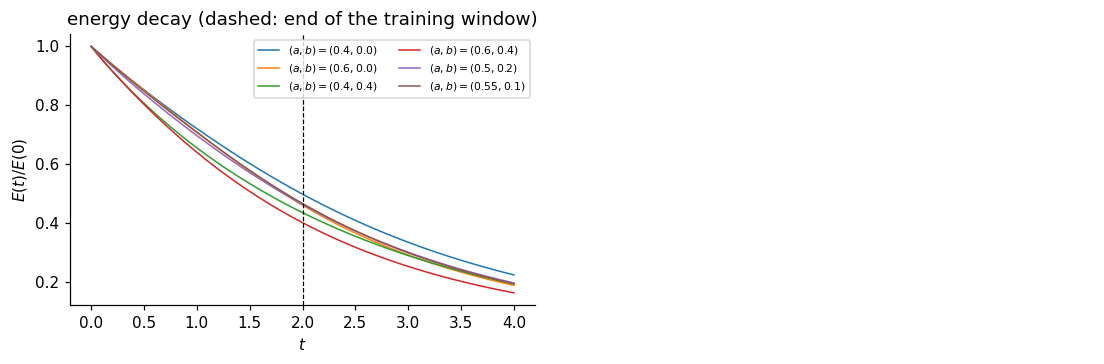

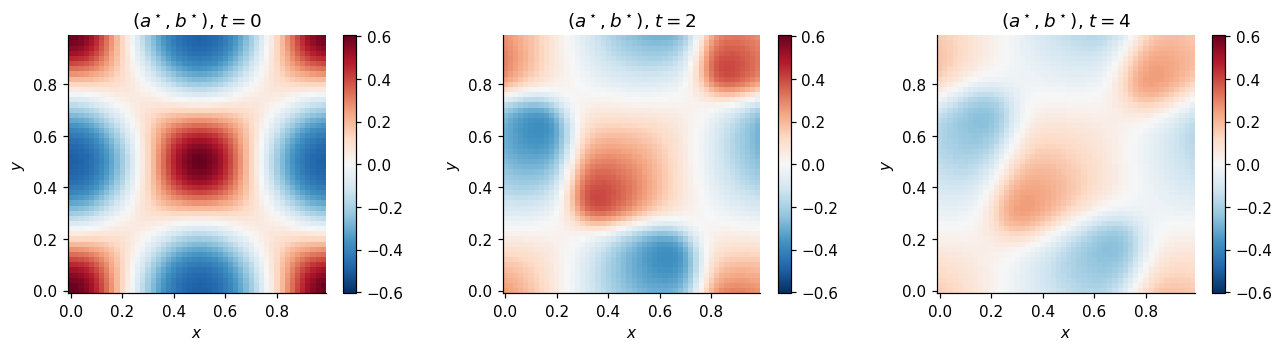

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for params in TRAIN_PARAMS + [TEST_PARAMS]:
    E = energy(truth[params])
    axes[0].plot(t_truth, E / E[0], lw=1.0, label=f"$(a,b)={params}$")
axes[0].axvline(T_TRAIN[1], color="k", ls="--", lw=0.8)
axes[0].set(xlabel="$t$", ylabel="$E(t)/E(0)$",
            title="energy decay (dashed: end of the training window)")
axes[0].legend(fontsize=7, ncol=2)

# the test field at three times
Q = truth[TEST_PARAMS]
for k, tk in enumerate([0.0, T_TRAIN[1], T_FINAL]):
    j = int(np.argmin(np.abs(t_truth - tk)))
    w = Q[:, j].reshape(NX, NX)
    ax = axes[1] if k == 1 else None
if True:
    fig2, axs2 = plt.subplots(1, 3, figsize=(12, 3.1))
    for ax, tk in zip(axs2, [0.0, T_TRAIN[1], T_FINAL]):
        j = int(np.argmin(np.abs(t_truth - tk)))
        w = Q[:, j].reshape(NX, NX)
        im = ax.pcolormesh(X, Y, w, shading="auto", cmap="RdBu_r",
                           vmin=-np.abs(Q).max(), vmax=np.abs(Q).max())
        ax.set(xlabel="$x$", ylabel="$y$", aspect="equal",
               title=f"$(a^\\star,b^\\star)$, $t={tk:g}$")
        fig2.colorbar(im, ax=ax)
axes[1].axis("off")
plt.tight_layout(); plt.show()

## 4. Sparse, noisy observations

### 4.1 Random observation times

Per trajectory, independently: $m=30$ times, the two endpoints of $[0,2]$ and $m-2$ sorted
uniform draws from it, rounded to the integration grid.

### 4.2 Relative noise

$$
\mathbf q_j = \mathbf q(t_j) + \boldsymbol\varepsilon_j,\qquad
\boldsymbol\varepsilon_j\sim\mathcal N\big(\mathbf 0,\ \mathrm{diag}(\xi\,\mathbf q(t_j))^2\big),
\qquad \xi = 0.03,
$$

entrywise $(\mathbf q_j)_i = w_i(t_j) + \xi|w_i(t_j)|z_{ij}$, with no noise at $t_0=0$ since the
initial condition is given. The same noise model and the same level as the other two problems.


In [10]:
def sample_times(m, t_span):
    # m sorted uniform times in t_span, endpoints forced, rounded to the DT grid.
    t = np.sort(np.random.uniform(t_span[0], t_span[1], size=m))
    t[0], t[-1] = t_span
    return on_grid(t)

def add_noise(Q, xi):
    # Relative Gaussian noise on all nodes, at times t_j with j >= 1.
    Qn = Q.copy()
    body = Q[:, 1:]                                  # skip the first column (t_0)
    Qn[:, 1:] = body + xi * np.abs(body) * np.random.standard_normal(body.shape)
    return Qn

np.random.seed(SEED)

obs_times = []        # list of L arrays, shape (m,)
snapshots_clean = []  # list of L arrays, shape (n, m): exact solution at those times
snapshots = []        # list of L arrays, shape (n, m): noisy  <- the ONLY training data
t0 = time.time()
for params in TRAIN_PARAMS:
    t_obs = sample_times(M, T_TRAIN)             # random draws 1: times
    Q_obs = solve_fom(*params, t_obs)            # exact solution at those times
    Q_noisy = add_noise(Q_obs, XI)               # random draws 2: noise
    obs_times.append(t_obs)
    snapshots_clean.append(Q_obs)
    snapshots.append(Q_noisy)

print(f"snapshots per trajectory: {snapshots[0].shape}   "
      f"total: {sum(S.shape[1] for S in snapshots)}   ({time.time()-t0:.1f} s)")

snapshots per trajectory: (2500, 30)   total: 150   (8.6 s)


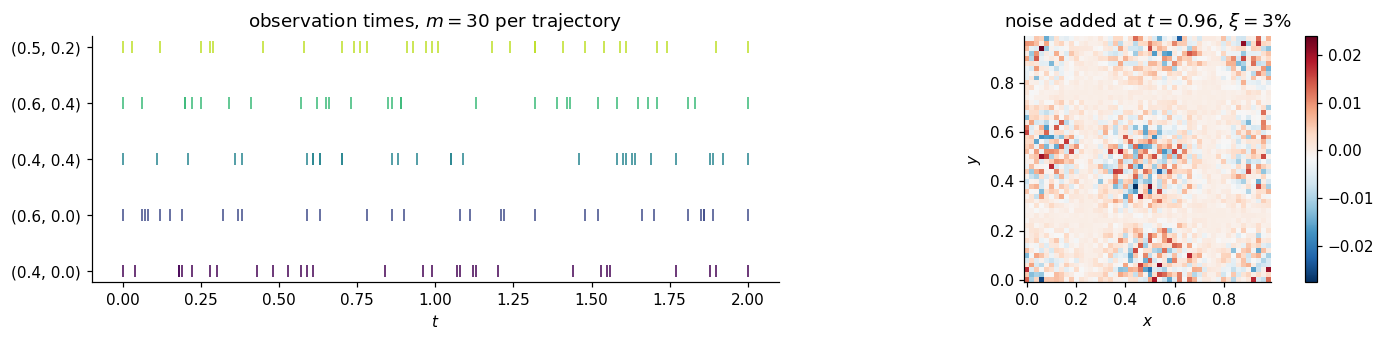

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(TRAIN_PARAMS)))

for l, (t_obs, params) in enumerate(zip(obs_times, TRAIN_PARAMS)):
    axes[0].plot(t_obs, np.full_like(t_obs, l), "|", ms=8, color=colors[l])
axes[0].set(xlabel="$t$", yticks=range(len(TRAIN_PARAMS)),
            yticklabels=[str(p) for p in TRAIN_PARAMS],
            title=f"observation times, $m={M}$ per trajectory")

# one noisy snapshot against the field it came from
l, j = 0, M // 2
clean = snapshots_clean[l][:, j].reshape(NX, NX)
noisy = snapshots[l][:, j].reshape(NX, NX)
im = axes[1].pcolormesh(X, Y, noisy - clean, shading="auto", cmap="RdBu_r")
axes[1].set(xlabel="$x$", ylabel="$y$", aspect="equal",
            title=f"noise added at $t={obs_times[l][j]:.2f}$, "
                  f"$\\xi={XI:.0%}$".replace("%", r"\%"))
fig.colorbar(im, ax=axes[1])
plt.tight_layout(); plt.show()

## 5. Compression

### 5.1 POD

As in the other two problems the basis is centred on the snapshot mean $\bar{\mathbf q}$: from
the thin SVD of all $L\times m$ noisy snapshots minus $\bar{\mathbf q}$ it is
$\mathbf V=\mathbf U_{:,1:r}$ with $r=6$, and
$\hat{\mathbf q}_j=\mathbf V^\top(\mathbf q_j-\bar{\mathbf q})$. The intrusive operators are

$$
\widehat{\mathbf H}=\mathbf V^\top\mathbf H_F(\mathbf V\otimes\mathbf V),\qquad
\widehat{\mathbf A}=\mathbf V^\top\big(\mathbf A_F+2\mathbf H_F(\bar{\mathbf q}\otimes\mathbf I)\big)\mathbf V,
\qquad
\hat{\mathbf c}=\mathbf V^\top\big(\mathbf A_F\bar{\mathbf q}+\mathbf H_F(\bar{\mathbf q}\otimes\bar{\mathbf q})\big).
$$

The amplitude of the initial field decides how far this basis can be pushed. Convection
transports the pattern across the square while viscosity damps it, and a subspace fitted to
$[0,2]$ represents $t=4$ well only if the transport over the prediction window is modest.
At the reference's amplitude $a\approx1$ the projection error at $t=4$ is about $0.4$,
so a reduced model of any kind is limited by the basis rather than by what it learned; at
$a\in[0.4,0.6]$ it is about $0.19$, and the experiment measures the inference instead.


In [12]:
Q_all = np.hstack(snapshots)                        # (n, L*m), noisy
q_bar = Q_all.mean(axis=1)                          # the mean snapshot profile

U_svd, svals, _ = np.linalg.svd(Q_all - q_bar[:, None], full_matrices=False)
cum = np.cumsum(svals**2) / np.sum(svals**2)
V = U_svd[:, :R]                                    # POD basis, (n, r)

def compress(Q):
    # Full snapshots (n, k) -> reduced coordinates (r, k)
    return V.T @ (Q - q_bar[:, None])

def decompress(Q_hat):
    # Reduced coordinates (r, k) -> full state (n, k)
    return V @ Q_hat + q_bar[:, None]

print(f"snapshot matrix: {Q_all.shape}")
print(f"energy captured by r = {R} modes: {cum[R-1]:.6f}   "
      f"(residual {1 - cum[R-1]:.3e})")


snapshot matrix: (2500, 150)
energy captured by r = 6 modes: 0.987941   (residual 1.206e-02)


In [13]:
# The intrusive operators about q_bar.  2 H_F(q_bar x v) is recovered from quad_split
# by polarization, as in problem 2.
Qbar = quad_split(q_bar)
Ahat = np.column_stack([V.T @ (A @ V[:, j]
                               + quad_split(q_bar + V[:, j]) - Qbar - quad_split(V[:, j]))
                        for j in range(R)])
chat = V.T @ (A @ q_bar + Qbar)
alpha = -np.linalg.eigvalsh(0.5 * (Ahat + Ahat.T)).max()

A_unshifted = V.T @ (A @ V)
ev = np.linalg.eigvalsh(0.5 * (A_unshifted + A_unshifted.T))
print(f"V' A_F V: symmetric negative definite, eigenvalues in "
      f"[{ev.min():.3e}, {ev.max():.3e}]")
print(f"||q_bar|| = {np.linalg.norm(q_bar):.4f}")
print(f"alpha of the intrusive ROM = {alpha:+.4f}   ||c_hat|| = {np.linalg.norm(chat):.4f}")
print("\nV' A_F V alone is negative definite, so the viscous part dissipates in every")
print("reduced direction.  The centring shift 2 H_F(q_bar x .) is not symmetric, so alpha")
print("is not simply that viscous rate; the value printed above is what it leaves.  What")
print("the inferred operators do with it is a question for the method notebook.")

V' A_F V: symmetric negative definite, eigenvalues in [-1.577e+00, -1.614e-01]
||q_bar|| = 10.5229
alpha of the intrusive ROM = +0.1286   ||c_hat|| = 3.2159

V' A_F V alone is negative definite, so the viscous part dissipates in every
reduced direction.  The centring shift 2 H_F(q_bar x .) is not symmetric, so alpha
is not simply that viscous rate; the value printed above is what it leaves.  What
the inferred operators do with it is a question for the method notebook.


/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83711/3731638156.py:10: RuntimeWarning: divide by zero encountered in matmul
  A_unshifted = V.T @ (A @ V)
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83711/3731638156.py:10: RuntimeWarning: overflow encountered in matmul
  A_unshifted = V.T @ (A @ V)
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83711/3731638156.py:10: RuntimeWarning: invalid value encountered in matmul
  A_unshifted = V.T @ (A @ V)


In [14]:
# The intrusive quadratic operator, in the compact form the method uses, and the
# check that it is energy preserving to machine precision.
pairs = [(i, j) for i in range(R) for j in range(i, R)]
Hhat = np.zeros((R, len(pairs)))
for col, (i, j) in enumerate(pairs):
    if i == j:
        Hhat[:, col] = V.T @ quad_split(V[:, i])
    else:                                   # polarization: H(a x b) + H(b x a)
        Hhat[:, col] = V.T @ (quad_split(V[:, i] + V[:, j])
                              - quad_split(V[:, i]) - quad_split(V[:, j]))

rng_ep = np.random.default_rng(1)
worst = 0.0
for _ in range(200):
    qh = rng_ep.standard_normal(R)
    kron_c = np.array([qh[i]*qh[j] for (i, j) in pairs])
    worst = max(worst, abs(qh @ (Hhat @ kron_c)) / np.linalg.norm(qh)**3)
print(f"max |q' H_hat (q x q)| over 200 random reduced states: {worst:.3e}")

max |q' H_hat (q x q)| over 200 random reduced states: 3.234e-17


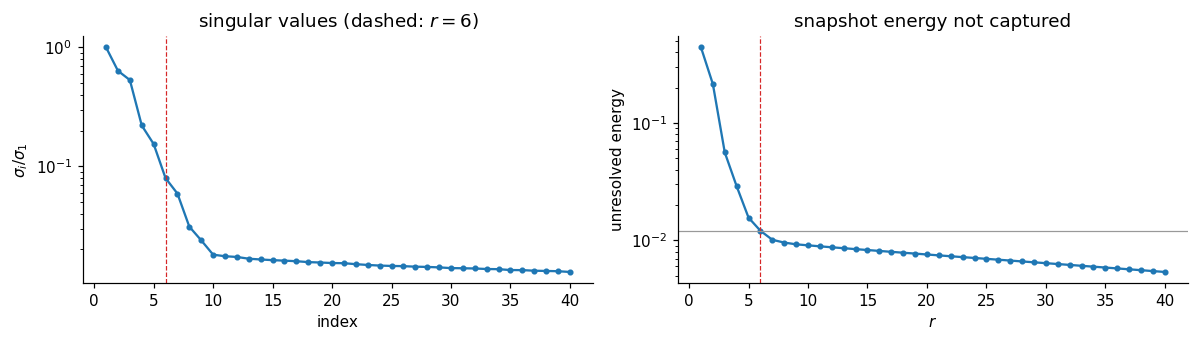

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
n_show_sv = 40
axes[0].semilogy(np.arange(1, n_show_sv+1), svals[:n_show_sv]/svals[0], "o-", ms=3)
axes[0].axvline(R, color="C3", ls="--", lw=0.8)
axes[0].set(xlabel="index", ylabel=r"$\sigma_i/\sigma_1$",
            title=f"singular values (dashed: $r={R}$)")
axes[1].plot(np.arange(1, n_show_sv+1), 1 - cum[:n_show_sv], "o-", ms=3)
axes[1].set_yscale("log")
axes[1].axvline(R, color="C3", ls="--", lw=0.8)
axes[1].axhline(1 - cum[R-1], color="0.6", lw=0.8)
axes[1].set(xlabel="$r$", ylabel="unresolved energy",
            title="snapshot energy not captured")
plt.tight_layout(); plt.show()

### 5.2 The reduced coordinate time series

For every trajectory $\ell$ and reduced coordinate $i$, the series that the Gaussian
processes of the method notebook are fitted to.


/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83711/996027491.py:10: RuntimeWarning: divide by zero encountered in matmul
  return V.T @ (Q - q_bar[:, None])
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83711/996027491.py:10: RuntimeWarning: overflow encountered in matmul
  return V.T @ (Q - q_bar[:, None])
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83711/996027491.py:10: RuntimeWarning: invalid value encountered in matmul
  return V.T @ (Q - q_bar[:, None])


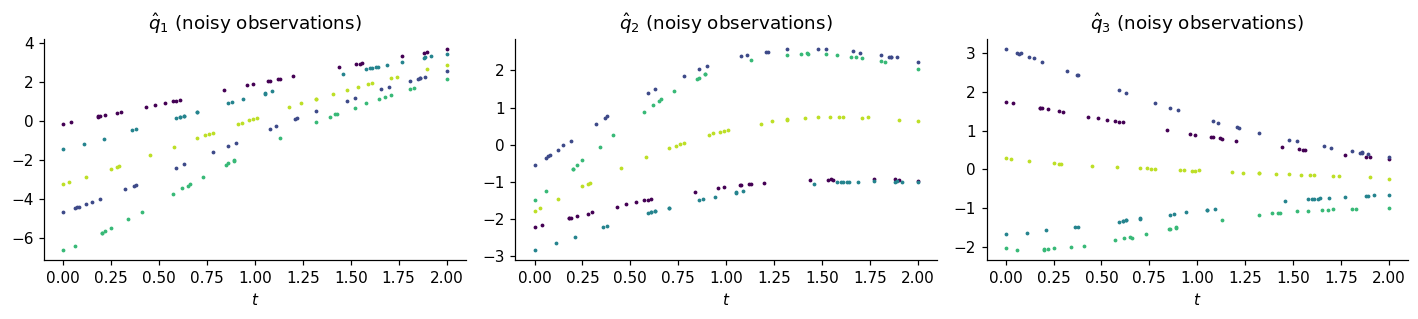

In [16]:
snapshots_compressed = [compress(S) for S in snapshots]           # list of (r, m)

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for i, ax in enumerate(axes):
    for l in range(len(TRAIN_PARAMS)):
        ax.plot(obs_times[l], snapshots_compressed[l][i], ".", ms=3, color=colors[l])
    ax.set(xlabel="$t$", title=f"$\\hat q_{{{i+1}}}$ (noisy observations)")
plt.tight_layout(); plt.show()

### 5.3 Projection error

$$
\frac{\|\mathbf Q_{\text{ref}} - \mathbf V\mathbf V^\top(\mathbf Q_{\text{ref}}-\bar{\mathbf q})-\bar{\mathbf q}\|_F}
     {\|\mathbf Q_{\text{ref}}\|_F},
$$

the floor below which no reduced model of this dimension can go, on the observation window and
over the whole horizon.


In [17]:
print(f"{'(a,b)':>14s}  {'proj. error [0,2]':>19s}  {'proj. error [0,4]':>19s}")
mask_tr = t_truth <= T_TRAIN[1]
for params in TRAIN_PARAMS + [TEST_PARAMS]:
    Q = truth[params]
    Qp = decompress(compress(Q))
    e_tr = np.linalg.norm(Q[:, mask_tr] - Qp[:, mask_tr]) / np.linalg.norm(Q[:, mask_tr])
    e_all = np.linalg.norm(Q - Qp) / np.linalg.norm(Q)
    tag = "  (test)" if params == TEST_PARAMS else ""
    print(f"{str(params):>14s}  {e_tr:19.4e}  {e_all:19.4e}{tag}")

         (a,b)    proj. error [0,2]    proj. error [0,4]
    (0.4, 0.0)           1.4388e-02           2.8098e-02
    (0.6, 0.0)           1.7704e-02           8.3610e-02
    (0.4, 0.4)           1.3460e-02           3.1142e-02
    (0.6, 0.4)           2.2769e-02           9.4746e-02
    (0.5, 0.2)           1.2055e-02           4.8614e-02
   (0.55, 0.1)           1.3433e-02           6.3633e-02  (test)


/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83711/996027491.py:10: RuntimeWarning: divide by zero encountered in matmul
  return V.T @ (Q - q_bar[:, None])
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83711/996027491.py:10: RuntimeWarning: overflow encountered in matmul
  return V.T @ (Q - q_bar[:, None])
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83711/996027491.py:10: RuntimeWarning: invalid value encountered in matmul
  return V.T @ (Q - q_bar[:, None])
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83711/996027491.py:14: RuntimeWarning: divide by zero encountered in matmul
  return V @ Q_hat + q_bar[:, None]
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83711/996027491.py:14: RuntimeWarning: overflow encountered in matmul
  return V @ Q_hat + q_bar[:, None]
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83711/996027491.py:14: RuntimeWarning: invalid value encountered in matmul
  return V @ Q_hat + q_b

## 6. Save the data

Everything the method notebook needs, plus the reference solutions for evaluation. The keys are
those of the other two problems, with `kappa` and `nu` in place of `gamma` and `eta`.


In [18]:
# The m' equally spaced times in [0, 2] at which the GP derivative estimates will be
# evaluated.  These are GP evaluation points, not FOM solves, so they need not lie on
# the DT grid.
t_est = np.linspace(*T_TRAIN, M_PRIME)

np.savez_compressed(
    "data_Burgers2D.npz",
    # configuration
    kappa=KAPPA, nu=NU, xi=XI, r=R, seed=SEED, P=P, dx=dx, dt=DT, nx=NX,
    train_params=np.array(TRAIN_PARAMS), test_params=np.array(TEST_PARAMS),
    x=x, y=y, t_truth=t_truth, t_est=t_est, t_train=np.array(T_TRAIN), t_final=T_FINAL,
    # training data (what the method is allowed to see)
    obs_times=np.array(obs_times),                       # (L, m)
    snapshots=np.array(snapshots),                       # (L, n, m)   noisy
    snapshots_clean=np.array(snapshots_clean),           # (L, n, m)   noise free
    snapshots_compressed=np.array(snapshots_compressed), # (L, r, m)
    # POD basis
    V=V, q_bar=q_bar, svals=svals,
    # A_F is not stored because it is fully determined by (nu, dx, nx): the five-point
    # Laplacian of section 2, three lines to rebuild.  There is no B_F and no input.
    # truth (for evaluation only)
    truth_train=np.array([truth[p] for p in TRAIN_PARAMS]),   # (L, n, 201)
    truth_test=truth[TEST_PARAMS],                            # (n, 201)
    energy_drift=np.array([energy_drift[p] for p in TRAIN_PARAMS + [TEST_PARAMS]]),
)

import os
print(f"saved data_Burgers2D.npz  ({os.path.getsize('data_Burgers2D.npz')/2**20:.1f} MiB)")

saved data_Burgers2D.npz  (25.0 MiB)


In [19]:
# Read it back and check the shapes, so the method notebook starts from known ground.
d = dict(np.load("data_Burgers2D.npz"))
for k in sorted(d):
    print(f"  {k:22s} {str(d[k].shape):16s} {d[k].dtype}")

  P                      ()               float64
  V                      (2500, 6)        float64
  dt                     ()               float64
  dx                     ()               float64
  energy_drift           (6, 201)         float64
  kappa                  ()               float64
  nu                     ()               float64
  nx                     ()               int64
  obs_times              (5, 30)          float64
  q_bar                  (2500,)          float64
  r                      ()               int64
  seed                   ()               int64
  snapshots              (5, 2500, 30)    float64
  snapshots_clean        (5, 2500, 30)    float64
  snapshots_compressed   (5, 6, 30)       float64
  svals                  (150,)           float64
  t_est                  (60,)            float64
  t_final                ()               float64
  t_train                (2,)             float64
  t_truth                (201,)           float64
  test